# Phân loại loại tin bằng PhoBERT + CNN

Mặc định `RUN_MODE = 'review'`: đọc checkpoint của lần chạy `20261024_153932_380173`, không train lại hoặc tự chạy test. Validation là phiên bản `validation_review_20261025_v2`: 6 nhãn và 3 nội dung đã được duyệt sửa; train/test, ID và thứ tự chia tập giữ nguyên.

Các sửa được đối chiếu qua `validation_revision.json`, có thể dựng ngược chính xác validation cũ để kiểm tra với checkpoint. STT 16 và 18 đã được người gán xác nhận cùng giữ `financial_results`; không còn bài chờ và không có CSV hoặc trọng số nào thay đổi vì xác nhận này.

Output số liệu được giữ từ lần đánh giá v2 trên Colab, không phải một lần suy luận mới. Báo cáo validation nằm riêng trong `reports/news_type/evaluations/validation_review_20261025_v2`. Test vẫn tắt cho đến khi có yêu cầu đánh giá.

## 1. Thiết lập

Khi chạy cục bộ, cài các gói trong `requirements.txt` và Java 8+ cho VnCoreNLP. Trên Colab, dùng các cell bên dưới để chuẩn bị môi trường GPU.

In [1]:
import gc
import hashlib
import json
import os
import shutil
import sys
import subprocess
import zipfile
from datetime import datetime
from importlib.metadata import version
from pathlib import Path
from urllib.request import urlretrieve

### Chạy trên Colab T4

Mở bản notebook 05 đã cập nhật, không giữ các cell tạm nạp model cũ. Khởi động lại phiên Python nếu đã import code cũ, rồi chạy từ đầu trên T4. Notebook ưu tiên ZIP trong thư mục Drive dự án; nếu chưa có, tải ZIP mới nhất vào `/content/news_processing_colab.zip`. Với `RUN_MODE = 'review'`, có thể dùng `Run all`: đọc checkpoint đã chỉ định, đánh giá validation, vẽ biểu đồ và xuất bảng rà lỗi; không huấn luyện hoặc đánh giá test.

ZIP cập nhật dữ liệu/code trong thư mục, không thay cell trong tab đang mở. Giữ nguyên PyTorch/CUDA; model và báo cáo ở `MyDrive/stock_news_anomaly_project`. Nếu checkpoint hoặc dữ liệu không khớp, notebook dừng thay vì tự train lại.

In [2]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import torch
    from packaging.version import Version
    if not torch.cuda.is_available():
        raise RuntimeError('Chưa có CUDA. Chọn máy GPU T4 trong Colab rồi kết nối lại.')
    if Version(torch.__version__.split('+')[0]) < Version('2.6'):
        raise RuntimeError('Cần runtime Colab có PyTorch >= 2.6; không tự thay bản CUDA hiện tại.')
    print('GPU được cấp:', torch.cuda.get_device_name(0))
    print('VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))

GPU được cấp: Tesla T4
VRAM (GB): 14.6


In [3]:
if IN_COLAB:
    colab_packages = [
        'transformers==4.57.1', 'py-vncorenlp==0.1.4',
        'pandas>=2.2,<3', 'scikit-learn>=1.7,<1.8',
        'matplotlib>=3.10,<4', 'tqdm>=4.67,<5',
    ]
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '--quiet', *colab_packages,
    ])
    if shutil.which('java') is None:
        subprocess.check_call(['apt-get', '-qq', 'update'])
        subprocess.check_call(['apt-get', '-qq', 'install', '-y', 'openjdk-17-jre-headless'])

In [4]:
COLAB_OUTPUT_DIR = None
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    COLAB_OUTPUT_DIR = Path('/content/drive/MyDrive/stock_news_anomaly_project')

Mounted at /content/drive


In [5]:
COLAB_PROJECT_DIR = Path('/content/news_processing') if IN_COLAB else None
if IN_COLAB:
    project_archive = COLAB_OUTPUT_DIR / 'news_processing_colab.zip'
    if not project_archive.is_file():
        project_archive = Path('/content/news_processing_colab.zip')
    if project_archive.is_file():
        with zipfile.ZipFile(project_archive) as archive:
            for member in archive.infolist():
                target_path = (Path('/content') / member.filename).resolve()
                if not target_path.is_relative_to(COLAB_PROJECT_DIR.resolve()):
                    raise ValueError('Gói ZIP phải chỉ chứa thư mục news_processing, không có đường dẫn bên ngoài.')
            archive.extractall('/content')
        print('Đã cập nhật dữ liệu/code từ:', project_archive)
    elif not COLAB_PROJECT_DIR.is_dir():
        raise FileNotFoundError('Dùng Upload to Colab để tải news_processing_colab.zip vào /content.')
    print('Dữ liệu/code:', COLAB_PROJECT_DIR)
    print('Nơi lưu checkpoint/báo cáo:', COLAB_OUTPUT_DIR)

Đã cập nhật dữ liệu/code từ: /content/drive/MyDrive/stock_news_anomaly_project/news_processing_colab.zip
Dữ liệu/code: /content/news_processing
Nơi lưu checkpoint/báo cáo: /content/drive/MyDrive/stock_news_anomaly_project


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, SequentialSampler
from tqdm.auto import tqdm
from transformers import AutoConfig, AutoModel, AutoTokenizer

In [7]:
CURRENT_DIR = Path.cwd().resolve()
PROJECT_CANDIDATES = ([COLAB_PROJECT_DIR] if IN_COLAB else []) + [
    CURRENT_DIR / 'news_processing', CURRENT_DIR, *CURRENT_DIR.parents,
]
PROJECT_DIR = next(
    (path for path in PROJECT_CANDIDATES
     if (path / 'src').is_dir() and (path / 'data').is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Không tìm thấy news_processing chứa src/ và data/.')
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

In [8]:
from src.model_data_utils import compute_balanced_class_weights, verify_model_splits
from src.phobert_cnn import EncodedNewsDataset, PhoBertCNN, encode_news_texts
from src.news_type_training import (
    build_validation_review,
    build_test_evaluation_manifest,
    evaluate_classifier,
    fit_classifier,
    load_saved_run_metadata,
    restore_saved_checkpoint,
    validate_saved_segmenter,
    make_optimizer,
    make_scheduler,
    seed_everything,
    run_parameter_study,
)

In [9]:
SPLIT_DIR = PROJECT_DIR / 'data/splits/news_type'
LABEL_MAPPING_PATH = PROJECT_DIR / 'models/news_type_phobert_cnn/label_mapping.json'
OUTPUT_ROOT = COLAB_OUTPUT_DIR if IN_COLAB else PROJECT_DIR
MODEL_DIR = OUTPUT_ROOT / 'models/news_type_phobert_cnn'
REPORT_DIR = OUTPUT_ROOT / 'reports/news_type'
VNCORENLP_DIR = PROJECT_DIR / 'models/vncorenlp'
MODEL_CACHE_DIR = PROJECT_DIR / 'models/huggingface'
VALIDATION_REVISION_PATH = PROJECT_DIR / 'data/annotation/news_type/validation_revision.json'

In [10]:
MODEL_NAME = 'vinai/phobert-base-v2'
MAX_LENGTH = 256
HEAD_RATIO = 0.75
KERNEL_SIZES = (2, 3, 4, 5)
NUM_FILTERS = 128
GLOBAL_PROJECTION_SIZE = 128
DROPOUT = 0.5
RANDOM_SEED = 42
RUN_MODE = 'review'
SAVED_RUN_NAME = '20261024_153932_380173'
RUN_PARAMETER_STUDY = False
EVALUATE_TEST = False
study_results = None

In [11]:
BATCH_SIZE = 8
BACKBONE_LR = 2e-5
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
MAX_EPOCHS = 8
PATIENCE = 2
MIN_DELTA = 1e-4
RUN_NAME = SAVED_RUN_NAME if RUN_MODE == 'review' else datetime.now().strftime('%Y%m%d_%H%M%S_%f')

In [12]:
java_executable_name = 'java.exe' if os.name == 'nt' else 'java'
java_home_candidates = [
    Path(os.environ[name]) for name in ('JAVA_HOME', 'JDK_HOME', 'JRE_HOME')
    if os.environ.get(name)
]
java_home_candidates.extend(sorted((PROJECT_DIR / 'models/java').glob('*')))
java_on_path = shutil.which('java')
if java_on_path:
    java_home_candidates.append(Path(java_on_path).resolve().parent.parent)
java_home = next(
    (path.resolve() for path in java_home_candidates
     if (path / 'bin' / java_executable_name).is_file()),
    None,
)
if java_home is not None:
    os.environ['JAVA_HOME'] = str(java_home)
    java_bin_path = str(java_home / 'bin')
    if java_bin_path not in os.environ.get('PATH', '').split(os.pathsep):
        os.environ['PATH'] = java_bin_path + os.pathsep + os.environ.get('PATH', '')

In [13]:
seed_everything(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
environment_summary = pd.DataFrame([
    {'item': 'PyTorch', 'value': torch.__version__},
    {'item': 'Transformers', 'value': version('transformers')},
    {'item': 'Thiết bị', 'value': str(DEVICE)},
    {'item': 'GPU', 'value': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'Không dùng'},
    {'item': 'Java trên PATH', 'value': shutil.which('java') or 'Chưa tìm thấy'},
])
display(environment_summary)

,item,value
0,PyTorch,2.11.0+cu130
1,Transformers,4.57.1
2,Thiết bị,cuda
3,GPU,Tesla T4
4,Java trên PATH,/usr/lib/jvm/java-21-openjdk-amd64/bin/java


## 2. Đọc và kiểm tra ba tập dữ liệu

Đối chiếu schema, nhãn và trùng lặp theo khóa nhận diện. Việc đọc test ở đây chỉ để kiểm tra toàn vẹn, không dùng để chọn cách tiền xử lý hay tham số huấn luyện. Các khóa này chưa kiểm soát được những bài khác nhau cùng nói về một sự kiện.

In [14]:
required_paths = [LABEL_MAPPING_PATH, *[SPLIT_DIR / f'{name}.csv'
                  for name in ('train', 'validation', 'test')]]
missing_paths = [str(path) for path in required_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError('Chạy cell lưu file của notebook 04 trước: ' + ', '.join(missing_paths))

label_mapping = json.loads(LABEL_MAPPING_PATH.read_text(encoding='utf-8-sig'))
if label_mapping.get('label_policy_version') != 'company_awards_listing_v2':
    raise ValueError('Sai phiên bản nhãn. Cập nhật ZIP mới trước khi huấn luyện.')
label2id = label_mapping['label2id']
ordered_labels = sorted(label2id, key=label2id.get)
NUM_CLASSES = len(ordered_labels)
if sorted(label2id.values()) != list(range(NUM_CLASSES)):
    raise ValueError('label_id phải liên tiếp từ 0 đến số lớp trừ 1.')
split_frames = {
    name: pd.read_csv(SPLIT_DIR / f'{name}.csv', dtype=str, keep_default_na=False)
    for name in ('train', 'validation', 'test')
}
input_file_hashes = {
    path.relative_to(PROJECT_DIR).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
    for path in required_paths
}

In [15]:
required_columns = {
    'news_id', 'canonical_news_id', 'url', 'title', 'content',
    'input_text', 'news_type', 'label_id', 'source', 'split',
}
for split_name, frame in split_frames.items():
    if not required_columns.issubset(frame.columns) or frame.empty:
        raise ValueError(f'{split_name}: file rỗng hoặc thiếu trường bắt buộc.')
    frame['label_id'] = pd.to_numeric(frame['label_id'], errors='raise')
    mapped_ids = frame['news_type'].map(label2id)
    if mapped_ids.isna().any() or not frame['label_id'].eq(mapped_ids).all():
        raise ValueError(f'{split_name}: news_type và label_id không khớp mapping.')
    frame['label_id'] = frame['label_id'].astype(int)
    if frame['news_id'].duplicated().any() or not frame['split'].eq(split_name).all():
        raise ValueError(f'{split_name}: trùng news_id hoặc sai tên tập.')

train_data = split_frames['train']
validation_data = split_frames['validation']

In [16]:
split_checks = verify_model_splits(
    full_eligible=pd.concat(list(split_frames.values()), ignore_index=True),
    train_df=train_data,
    val_df=validation_data,
    test_df=split_frames['test'],
    label2id=label2id,
)
# Đối chiếu khóa và nhãn; không dùng phép cộng số dòng làm bằng chứng đủ dữ liệu nguồn.
split_checks = split_checks.iloc[1:].reset_index(drop=True)
if not split_checks['issue_count'].eq(0).all():
    display(split_checks)
    raise ValueError('Các tập chưa đạt kiểm tra; cần xem lại notebook 04.')
print('Số bài:', {name: len(frame) for name, frame in split_frames.items()})
print('Số lớp:', NUM_CLASSES, '| Kiểm tra khóa và nhãn: đạt')

Số bài: {'train': 740, 'validation': 159, 'test': 159}
Số lớp: 7 | Kiểm tra khóa và nhãn: đạt


In [17]:
class_weights_table = compute_balanced_class_weights(train_data, label2id)
train_distribution = class_weights_table.copy()
train_distribution['display_name'] = train_distribution['news_type'].map(
    label_mapping.get('display_names', {})
)
display(train_distribution[['news_type', 'train_count', 'class_weight']])

,news_type,train_count,class_weight
0,governance_capital,106,0.9973
1,financial_results,124,0.8525
2,business_operations,208,0.5082
3,legal_compliance,36,2.9365
4,industry,64,1.6518
5,stock_market,143,0.7393
6,mention_only,59,1.7918


In [18]:
if RUN_MODE not in {'train', 'review'}:
    raise ValueError("RUN_MODE chỉ nhận 'train' hoặc 'review'.")
if RUN_MODE == 'review' and RUN_PARAMETER_STUDY:
    raise ValueError('Chế độ review không chạy khảo sát tham số.')
SAVED_MODEL_DIR = SAVED_REPORT_DIR = None
if RUN_MODE == 'review':
    if (not isinstance(SAVED_RUN_NAME, str) or not SAVED_RUN_NAME
            or SAVED_RUN_NAME in {'.', '..'} or '/' in SAVED_RUN_NAME or '\\' in SAVED_RUN_NAME):
        raise ValueError('SAVED_RUN_NAME phải là tên một lần chạy, không phải đường dẫn.')
    SAVED_MODEL_DIR = (MODEL_DIR / 'runs' / SAVED_RUN_NAME).resolve()
    SAVED_REPORT_DIR = (REPORT_DIR / 'runs' / SAVED_RUN_NAME).resolve()
    if (SAVED_MODEL_DIR.parent != (MODEL_DIR / 'runs').resolve()
            or SAVED_REPORT_DIR.parent != (REPORT_DIR / 'runs').resolve()):
        raise ValueError('Lần chạy phải nằm trong thư mục runs đã chỉ định.')

In [19]:
validation_revision = None
if VALIDATION_REVISION_PATH.is_file():
    validation_revision = json.loads(VALIDATION_REVISION_PATH.read_text(encoding='utf-8-sig'))
elif RUN_MODE == 'review':
    raise FileNotFoundError('Thiếu hồ sơ cập nhật validation đã duyệt. Cập nhật ZIP mới.')
if EVALUATE_TEST and validation_revision and validation_revision.get('pending_reviews'):
    raise RuntimeError('Còn bài chưa chốt nhãn; không đánh giá test trong phiên này.')

In [20]:
if RUN_MODE == 'review':
    expected_saved_weights = torch.tensor(
        class_weights_table.sort_values('label_id')['class_weight'].tolist(), dtype=torch.float32,
    ).tolist()
    expected_saved_parameters = {
        'model_name': MODEL_NAME, 'max_length': MAX_LENGTH, 'head_ratio': HEAD_RATIO,
        'word_segmenter': 'VnCoreNLP wseg 1.2',
        'pooling_special_tokens': 'include; padding excluded',
        'kernel_sizes': list(KERNEL_SIZES), 'num_filters': NUM_FILTERS,
        'global_projection_size': GLOBAL_PROJECTION_SIZE, 'dropout': DROPOUT,
        'num_classes': NUM_CLASSES,
        'class_weights_by_id': expected_saved_weights,
    }
    run_config, history = load_saved_run_metadata(
        SAVED_MODEL_DIR, SAVED_REPORT_DIR, input_sha256=input_file_hashes,
        label_mapping=label_mapping, expected_config=expected_saved_parameters,
        validation_revision=validation_revision, validation_path=SPLIT_DIR / 'validation.csv',
    )
    print('Đọc lại lần chạy:', SAVED_RUN_NAME, '| Không huấn luyện lại.')

Đọc lại lần chạy: 20261024_153932_380173 | Không huấn luyện lại.


## 3. Kiểm tra điều kiện chạy

Trên Colab, cần có CUDA trước khi chuẩn bị dữ liệu. Khi chạy cục bộ, notebook vẫn cho phép CPU và báo thời gian huấn luyện có thể dài. Java portable trong `models/java` chỉ dùng cho kernel hiện tại; Colab dùng Java Linux, không dùng bản Windows.

In [21]:
if DEVICE.type == 'cpu':
    print('Đang chạy CPU; huấn luyện PhoBERT có thể mất nhiều thời gian.')
if shutil.which('java') is None:
    raise RuntimeError(
        'Chưa tìm thấy Java. Chuẩn bị Java 8+ hoặc Java portable trong '
        'models/java, sau đó Restart Kernel và chạy lại notebook.'
    )
print('Java đã sẵn sàng cho bước tách từ.')

Java đã sẵn sàng cho bước tách từ.


## 4. Tách từ và mã hóa văn bản

Dùng VnCoreNLP trước BPE theo [hướng dẫn PhoBERT](https://huggingface.co/vinai/phobert-base-v2#notes). Chỉ tải ba thành phần cần cho tách từ, không tải bộ POS/NER/parser.

Head–Tail ưu tiên 75% ngân sách cho đầu bài, giữ phần còn lại ở cuối bài. Đây là cấu hình khởi đầu, chưa phải tỷ lệ tối ưu. Cắt trên BPE token trước khi thêm `<s>` và `</s>`: tối đa 254 token nội dung, tổng chiều dài 256. Phần giữa bị bỏ khi bài vượt giới hạn.

In [22]:
vncorenlp_base_url = 'https://raw.githubusercontent.com/vncorenlp/VnCoreNLP/master/'
vncorenlp_resources = (
    'VnCoreNLP-1.2.jar',
    'models/wordsegmenter/vi-vocab',
    'models/wordsegmenter/wordsegmenter.rdr',
)
for relative_path in vncorenlp_resources:
    resource_path = VNCORENLP_DIR / relative_path
    if resource_path.is_file() and resource_path.stat().st_size > 0:
        continue
    resource_path.parent.mkdir(parents=True, exist_ok=True)
    download_path = resource_path.with_name(resource_path.name + '.part')
    urlretrieve(vncorenlp_base_url + relative_path, str(download_path))
    if download_path.stat().st_size == 0:
        raise RuntimeError(f'Tải tài nguyên không thành công: {relative_path}')
    download_path.replace(resource_path)

In [23]:
segmenter_file_hashes = {
    relative_path: hashlib.sha256((VNCORENLP_DIR / relative_path).read_bytes()).hexdigest()
    for relative_path in vncorenlp_resources
}
if RUN_MODE == 'review':
    validate_saved_segmenter(run_config, segmenter_file_hashes)

In [24]:
import py_vncorenlp

working_directory = Path.cwd()
try:
    segmenter = py_vncorenlp.VnCoreNLP(annotators=['wseg'], save_dir=str(VNCORENLP_DIR))
finally:
    # Wrapper đổi working directory khi khởi tạo; trả lại thư mục notebook.
    os.chdir(working_directory)

In [25]:
tokenizer_source = SAVED_MODEL_DIR / 'tokenizer' if RUN_MODE == 'review' else MODEL_NAME
tokenizer = AutoTokenizer.from_pretrained(
    str(tokenizer_source), use_fast=False, cache_dir=str(MODEL_CACHE_DIR),
    local_files_only=RUN_MODE == 'review',
)
print('Ngân sách token nội dung:', MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False))

Ngân sách token nội dung: 254


In [26]:
train_encodings = encode_news_texts(
    tqdm(train_data['input_text'], desc='Mã hóa train'), segmenter, tokenizer,
    max_length=MAX_LENGTH, head_ratio=HEAD_RATIO,
)

Mã hóa train:   0%|          | 0/740 [00:00<?, ?it/s]

In [27]:
validation_encodings = encode_news_texts(
    tqdm(validation_data['input_text'], desc='Mã hóa validation'), segmenter, tokenizer,
    max_length=MAX_LENGTH, head_ratio=HEAD_RATIO,
)

Mã hóa validation:   0%|          | 0/159 [00:00<?, ?it/s]

In [28]:
train_token_lengths = pd.Series([
    item['original_token_count'] for item in train_encodings
])
content_budget = MAX_LENGTH - tokenizer.num_special_tokens_to_add(pair=False)
truncated_train_count = int(train_token_lengths.gt(content_budget).sum())
display(pd.DataFrame([
    {'metric': 'Token nội dung trung vị trước cắt', 'value': train_token_lengths.median()},
    {'metric': 'Token nội dung P95 trước cắt', 'value': train_token_lengths.quantile(0.95)},
    {'metric': 'Bài train bị cắt', 'value': truncated_train_count},
    {'metric': 'Tỷ lệ train bị cắt (%)', 'value': round(truncated_train_count / len(train_data) * 100, 2)},
]))

,metric,value
0,Token nội dung trung vị trước cắt,717.00
1,Token nội dung P95 trước cắt,1347.60
2,Bài train bị cắt,716.00
3,Tỷ lệ train bị cắt (%),96.76


## 5. Tạo batch

Chỉ xáo trộn train. Validation và test giữ thứ tự để ghép dự đoán đúng với `news_id`. Dùng `num_workers=0` để tránh khởi tạo lại JVM trong notebook Windows.

In [29]:
train_dataset = EncodedNewsDataset(train_encodings, train_data['label_id'].tolist())
validation_dataset = EncodedNewsDataset(
    validation_encodings, validation_data['label_id'].tolist(),
)
train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_generator, num_workers=0, pin_memory=DEVICE.type == 'cuda',
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=DEVICE.type == 'cuda',
)

## 6. Khởi tạo PhoBERT + TextCNN

PhoBERT tạo biểu diễn theo ngữ cảnh; bốn nhánh CNN lấy đặc trưng từ cửa sổ 2–5 token. Sau GELU, loại cửa sổ có padding trước max pooling. Nhánh masked mean lấy trung bình các vị trí không phải padding rồi giảm từ 768 xuống 128 chiều. Hai nhánh đều giữ special token.

```text
PhoBERT: [B, 256, 768]
    ├─ Conv1D k=2,3,4,5; mỗi nhánh 128 filters
    │    → GELU → mask cửa sổ → Max Pool → ghép 512 chiều
    └─ Masked Mean Pool → Linear(768, 128) → 128 chiều
Ghép 640 → LayerNorm → Dropout(0.5) → Linear(640, 7)
```

Đầu ra là logits, không áp dụng Softmax trước Cross-Entropy.

In [30]:
if RUN_MODE == 'review':
    backbone_config = AutoConfig.from_pretrained(
        str(SAVED_MODEL_DIR / 'backbone'), local_files_only=True,
    )
    backbone = AutoModel.from_config(backbone_config)
else:
    backbone = AutoModel.from_pretrained(MODEL_NAME, cache_dir=str(MODEL_CACHE_DIR))
model = PhoBertCNN(
    backbone=backbone, num_classes=NUM_CLASSES,
    kernel_sizes=KERNEL_SIZES, num_filters=NUM_FILTERS,
    global_projection_size=GLOBAL_PROJECTION_SIZE, dropout=DROPOUT,
).to(DEVICE)
print('Số chiều trước classifier:', model.feature_size)
print('Tham số được huấn luyện:', f'{sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

Số chiều trước classifier: 640
Tham số được huấn luyện: 136,479,239


In [31]:
if RUN_MODE == 'review':
    restored_checkpoint = restore_saved_checkpoint(model, SAVED_MODEL_DIR, run_config, DEVICE)
    print('Checkpoint đã nạp:', SAVED_RUN_NAME, '| Epoch:', restored_checkpoint['epoch'])

Checkpoint đã nạp: 20261024_153932_380173 | Epoch: 2


In [32]:
example_batch = next(iter(validation_loader))
model.eval()
with torch.no_grad():
    example_logits = model(
        input_ids=example_batch['input_ids'].to(DEVICE),
        attention_mask=example_batch['attention_mask'].to(DEVICE),
    )
assert example_logits.shape == (len(example_batch['labels']), NUM_CLASSES)
assert torch.isfinite(example_logits).all()
print('Shape logits của một batch:', tuple(example_logits.shape))

Shape logits của một batch: (8, 7)


## 7. Loss và cập nhật trọng số

Weighted Cross-Entropy dùng trọng số nghịch đảo tần suất chỉ tính từ train. Fine-tune toàn bộ PhoBERT với learning rate nhỏ hơn phần CNN/classifier mới khởi tạo. AdamW đi cùng warmup, giảm learning rate tuyến tính và gradient clipping; các giá trị trên là cấu hình thử nghiệm, không phải kết quả đã tối ưu.

In [33]:
class_weights = torch.tensor(
    class_weights_table.sort_values('label_id')['class_weight'].tolist(),
    dtype=torch.float32, device=DEVICE,
)
criterion = nn.CrossEntropyLoss(weight=class_weights)

In [34]:
if RUN_MODE == 'train':
    optimizer = make_optimizer(
        model, backbone_lr=BACKBONE_LR, head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY,
    )
    scheduler = make_scheduler(
        optimizer, total_steps=len(train_loader) * MAX_EPOCHS, warmup_ratio=WARMUP_RATIO,
    )

## 8. Huấn luyện và chọn checkpoint

Ở chế độ `train`, lưu checkpoint có Macro-F1 validation cao nhất và dừng sớm theo `MIN_DELTA`/`PATIENCE`; mỗi lần chạy tạo thư mục riêng. Ở chế độ `review`, dùng trọng số và lịch sử đã xác minh, không tạo optimizer hoặc chạy epoch mới.

Lịch sử và đồ thị theo epoch bên dưới thuộc lần train nguồn, trước khi sửa validation. Chúng không phải điểm trên phiên bản dữ liệu mới; kết quả đánh giá lại được tính ở mục 9.

In [35]:
RUN_MODEL_DIR = SAVED_MODEL_DIR if RUN_MODE == 'review' else MODEL_DIR / 'runs' / RUN_NAME
evaluation_revision = history.attrs.get('evaluation_revision') if RUN_MODE == 'review' else None
RUN_REPORT_DIR = (
    REPORT_DIR / 'evaluations' / evaluation_revision if evaluation_revision
    else SAVED_REPORT_DIR if RUN_MODE == 'review' else REPORT_DIR / 'runs' / RUN_NAME
)
CHECKPOINT_PATH = RUN_MODEL_DIR / 'best_model.pt'
if RUN_MODE == 'train' and (RUN_MODEL_DIR.exists() or RUN_REPORT_DIR.exists()):
    raise FileExistsError('RUN_NAME đã tồn tại. Chọn tên mới trước khi huấn luyện.')
if evaluation_revision:
    RUN_REPORT_DIR.mkdir(parents=True, exist_ok=True)
print('Thư mục model:', RUN_MODEL_DIR)
print('Thư mục báo cáo:', RUN_REPORT_DIR)

Thư mục model: /content/drive/MyDrive/stock_news_anomaly_project/models/news_type_phobert_cnn/runs/20261024_153932_380173
Thư mục báo cáo: /content/drive/MyDrive/stock_news_anomaly_project/reports/news_type/evaluations/validation_review_20261025_v2


In [36]:
if RUN_MODE == 'train':
    history = fit_classifier(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        optimizer=optimizer,
        scheduler=scheduler,
        criterion=criterion,
        device=DEVICE,
        num_classes=NUM_CLASSES,
        checkpoint_path=CHECKPOINT_PATH,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
        min_delta=MIN_DELTA,
    )
else:
    print('Dùng checkpoint đã lưu; bỏ qua huấn luyện.')

Dùng checkpoint đã lưu; bỏ qua huấn luyện.


In [37]:
display(history.round(4))
print('Epoch tốt nhất:', history.attrs['best_epoch'])
print('Macro-F1 validation tốt nhất:', round(history.attrs['best_validation_macro_f1'], 4))

,epoch,train_loss,train_accuracy,train_macro_f1,validation_loss,validation_accuracy,validation_macro_f1,is_best
0,1,1.4385,0.5108,0.5003,0.7189,0.7862,0.7514,True
1,2,0.6921,0.7946,0.7920,0.6069,0.8868,0.8792,True
2,3,0.3722,0.8878,0.8746,0.5996,0.8805,0.8781,False
3,4,0.1855,0.9554,0.9503,0.8742,0.8868,0.8677,False


Epoch tốt nhất: 2
Macro-F1 validation tốt nhất: 0.8792


In [38]:
def plot_training_history(training_history, best_epoch):
    figure, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for axis, metric, title in zip(axes, ('loss', 'accuracy', 'macro_f1'),
                                   ('Loss', 'Accuracy', 'Macro-F1')):
        axis.plot(training_history['epoch'], training_history['train_' + metric],
                  marker='o', label='Train')
        axis.plot(training_history['epoch'], training_history['validation_' + metric],
                  marker='o', label='Validation')
        axis.axvline(best_epoch, color='gray', linestyle='--', label='Checkpoint chọn')
        axis.set(title=title, xlabel='Epoch', ylabel=title)
        axis.set_xticks(training_history['epoch'])
        if metric != 'loss':
            axis.set_ylim(0, 1.05)
        axis.legend(fontsize=8)
    figure.tight_layout()
    return figure

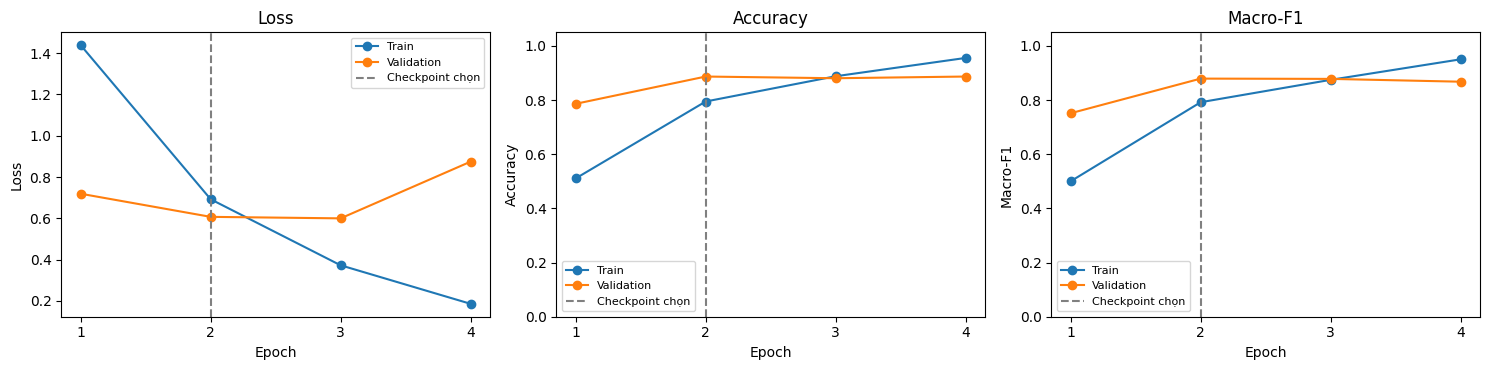

In [39]:
baseline_history_figure = plot_training_history(history, history.attrs['best_epoch'])
plt.show()

## 9. Đánh giá trên validation

Xem kết quả từng nhãn của checkpoint đã chọn. Train loss được tổng hợp từ các batch trong lúc cập nhật trọng số; không coi đó là phép đánh giá lại toàn bộ train bằng checkpoint cuối.

In [40]:
validation_results = evaluate_classifier(
    model, validation_loader, DEVICE, NUM_CLASSES, criterion=criterion,
)
metric_names = ('loss', 'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy')
validation_metrics = {name: validation_results[name] for name in metric_names}
display(pd.DataFrame([validation_metrics]).round(4))

,loss,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,0.5214,0.9308,0.9107,0.9297,0.9062


In [41]:
if RUN_MODE == 'review' and not history.attrs.get('evaluation_revision'):
    saved_f1 = run_config['best_validation_macro_f1']
    if abs(validation_metrics['macro_f1'] - saved_f1) > 1e-8:
        raise RuntimeError('Macro-F1 đánh giá lại không khớp lần đã lưu; dừng trước khi xuất báo cáo.')
elif RUN_MODE == 'review':
    print('Đánh giá validation đã sửa:', history.attrs['evaluation_revision'])
    print('Điểm thuộc phiên bản validation đã sửa, không phải cải thiện do train lại.')
    pending_count = len(validation_revision.get('pending_reviews', []))
    print('Bài còn chờ quyết định:', pending_count)
    if pending_count == 0:
        print('Đã xác nhận nhãn các bài từng chờ; không cần tính lại điểm vì dữ liệu không đổi.')

Đánh giá validation đã sửa: validation_review_20261025_v2
Điểm thuộc phiên bản validation đã sửa, không phải cải thiện do train lại.
Bài còn chờ quyết định: 0
Đã xác nhận nhãn các bài từng chờ; không cần tính lại điểm vì dữ liệu không đổi.


In [42]:
validation_class_report = pd.DataFrame(classification_report(
    validation_results['labels'], validation_results['predictions'],
    labels=list(range(NUM_CLASSES)), target_names=ordered_labels,
    output_dict=True, zero_division=0,
)).T
display(validation_class_report.round(4))

,precision,recall,f1-score,support
governance_capital,0.9231,1.0000,0.9600,24.0000
financial_results,0.8750,0.8400,0.8571,25.0000
business_operations,0.9796,0.9796,0.9796,49.0000
legal_compliance,1.0000,0.8571,0.9231,7.0000
industry,0.9333,0.7778,0.8485,18.0000
stock_market,0.9310,1.0000,0.9643,27.0000
mention_only,0.8000,0.8889,0.8421,9.0000
accuracy,0.9308,0.9308,0.9308,0.9308
macro avg,0.9203,0.9062,0.9107,159.0000
weighted avg,0.9319,0.9308,0.9297,159.0000


## 10. Lưu mô hình và kết quả chạy

Chế độ `train` lưu cấu hình, tokenizer, backbone config, lịch sử và kết quả validation cùng checkpoint. Chế độ `review` giữ nguyên các tệp đã lưu; chỉ các biểu đồ và bảng rà lỗi ở mục sau được tạo lại.

Trên Colab, đầu ra nằm trên Drive. Checkpoint không lưu optimizer/scheduler nên không phải cơ chế tiếp tục chính xác một epoch bị ngắt.

In [43]:
if RUN_MODE == 'train':
    run_config = {
        'model_name': MODEL_NAME,
        'model_revision': getattr(backbone.config, '_commit_hash', None),
        'max_length': MAX_LENGTH, 'head_ratio': HEAD_RATIO,
        'word_segmenter': 'VnCoreNLP wseg 1.2',
        'pooling_special_tokens': 'include; padding excluded',
        'kernel_sizes': list(KERNEL_SIZES), 'num_filters': NUM_FILTERS,
        'global_projection_size': GLOBAL_PROJECTION_SIZE, 'dropout': DROPOUT,
        'num_classes': NUM_CLASSES, 'label_mapping': label_mapping,
        'seed': RANDOM_SEED, 'batch_size': BATCH_SIZE,
        'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR,
        'weight_decay': WEIGHT_DECAY, 'warmup_ratio': WARMUP_RATIO,
        'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'min_delta': MIN_DELTA,
        'max_grad_norm': 1.0, 'precision': 'float32', 'device': str(DEVICE),
        'best_epoch': int(history.attrs['best_epoch']),
        'best_validation_macro_f1': float(history.attrs['best_validation_macro_f1']),
        'class_weights_by_id': class_weights.detach().cpu().tolist(),
        'versions': {name: version(name) for name in (
            'torch', 'transformers', 'py-vncorenlp', 'numpy', 'pandas', 'scikit-learn',
        )},
    }

In [44]:
if RUN_MODE == 'train':
    run_config['input_sha256'] = input_file_hashes
    run_config['segmenter_sha256'] = segmenter_file_hashes
    RUN_REPORT_DIR.mkdir(parents=True, exist_ok=False)
    tokenizer.save_pretrained(str(RUN_MODEL_DIR / 'tokenizer'))
    backbone.config.save_pretrained(str(RUN_MODEL_DIR / 'backbone'))
    (RUN_MODEL_DIR / 'run_config.json').write_text(
        json.dumps(run_config, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )

In [45]:
if RUN_MODE == 'train':
    history.to_csv(RUN_REPORT_DIR / 'training_history.csv', index=False, encoding='utf-8-sig')
    validation_class_report.to_csv(
        RUN_REPORT_DIR / 'validation_classification_report.csv', encoding='utf-8-sig',
    )
    (RUN_REPORT_DIR / 'validation_metrics.json').write_text(
        json.dumps(validation_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )
    print('Đã lưu checkpoint, cấu hình và báo cáo validation vào:', RUN_NAME)
    baseline_history_figure.savefig(RUN_REPORT_DIR / 'training_curves.png', dpi=160)
else:
    print('Giữ nguyên checkpoint, cấu hình, lịch sử và chỉ số đã lưu.')

Giữ nguyên checkpoint, cấu hình, lịch sử và chỉ số đã lưu.


In [46]:
if RUN_MODE == 'review' and evaluation_revision:
    evaluation_config = {
        'source_run': SAVED_RUN_NAME, 'evaluation_revision': evaluation_revision,
        'checkpoint_epoch': restored_checkpoint['epoch'], 'model_retrained': False,
        'training_label_policy': run_config['label_mapping']['label_policy_version'],
        'evaluation_label_policy': label_mapping['label_policy_version'],
        'training_input_sha256': run_config['input_sha256'],
        'evaluation_input_sha256': input_file_hashes,
        'revision_sha256': hashlib.sha256(VALIDATION_REVISION_PATH.read_bytes()).hexdigest(),
        'pending_reviews': validation_revision['pending_reviews'],
        'resolved_reviews': validation_revision.get('resolved_reviews', []),
        'label_review_complete': not validation_revision['pending_reviews'], 'final_evaluation': False,
        'evaluated_split': 'validation', 'test_evaluated': False,
    }
    (RUN_REPORT_DIR / 'evaluation_config.json').write_text(
        json.dumps(evaluation_config, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )

In [47]:
if RUN_MODE == 'review' and evaluation_revision:
    validation_class_report.to_csv(
        RUN_REPORT_DIR / 'validation_classification_report.csv', encoding='utf-8-sig',
    )
    (RUN_REPORT_DIR / 'validation_metrics.json').write_text(
        json.dumps(validation_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )
    print('Đã lưu kết quả validation phiên bản mới:', RUN_REPORT_DIR)

Đã lưu kết quả validation phiên bản mới: /content/drive/MyDrive/stock_news_anomaly_project/reports/news_type/evaluations/validation_review_20261025_v2


## 11. Khảo sát tham số

Phần này đang tắt (`RUN_PARAMETER_STUDY = False`); các cell không chạy thêm mô hình. Chỉ bật khi chủ động muốn khảo sát lại.

So sánh sáu cấu hình: bốn cặp learning rate, một cấu hình tăng dropout và một cấu hình tăng weight decay. Hai cách tăng regularization được so với cấu hình gốc, chưa kết hợp đồng thời. Giữ nguyên dữ liệu, kiến trúc, cách cắt token, batch size và ngân sách epoch để tránh trộn nhiều thay đổi.

Mỗi lần thử khởi tạo lại PhoBERT, CNN, optimizer và bộ xáo trộn train. Chọn theo Macro-F1 validation; nếu bằng nhau, xét Accuracy rồi validation loss. Accuracy và F1 luôn lấy từ cùng checkpoint. Không dùng test trong khảo sát. [Tái lập trong PyTorch](https://docs.pytorch.org/docs/2.9/notes/randomness.html), [tách validation và test](https://scikit-learn.org/1.7/modules/cross_validation.html).

In [48]:
trial_columns = ['trial_id', 'backbone_lr', 'head_lr', 'dropout', 'weight_decay']
trial_settings = [
    ('baseline',      2e-5, 1e-3, 0.3, 0.01),
    ('head_lr',       2e-5, 3e-4, 0.3, 0.01),
    ('backbone_lr',   1e-5, 1e-3, 0.3, 0.01),
    ('both_lr',       1e-5, 3e-4, 0.3, 0.01),
    ('dropout',       2e-5, 1e-3, 0.5, 0.01),
    ('weight_decay',  2e-5, 1e-3, 0.3, 0.05),
]
trial_configs = [dict(zip(trial_columns, values)) for values in trial_settings]
if RUN_PARAMETER_STUDY:
    display(pd.DataFrame(trial_configs))

In [49]:
STUDY_NAME = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
STUDY_MODEL_DIR = MODEL_DIR / 'studies' / STUDY_NAME
STUDY_REPORT_DIR = REPORT_DIR / 'studies' / STUDY_NAME
baseline_metrics = validation_metrics.copy()
baseline_model_dir = RUN_MODEL_DIR
baseline_report_dir = RUN_REPORT_DIR
if RUN_PARAMETER_STUDY:
    print('Model khảo sát:', STUDY_MODEL_DIR)
    print('Báo cáo khảo sát:', STUDY_REPORT_DIR)

In [50]:
fixed_parameter_names = (
    'model_name', 'model_revision', 'max_length', 'head_ratio', 'word_segmenter',
    'pooling_special_tokens', 'kernel_sizes', 'num_filters', 'global_projection_size',
    'num_classes', 'label_mapping', 'batch_size', 'precision', 'max_grad_norm',
    'class_weights_by_id', 'input_sha256', 'segmenter_sha256', 'versions',
)
if RUN_PARAMETER_STUDY:
    study_context = {name: run_config[name] for name in fixed_parameter_names}
    study_context['training_code_sha256'] = hashlib.sha256(
        (PROJECT_DIR / 'src/news_type_training.py').read_bytes()
    ).hexdigest()

In [51]:
def build_trial_model(parameters):
    trial_backbone = AutoModel.from_pretrained(
        MODEL_NAME, revision=study_context['model_revision'], cache_dir=str(MODEL_CACHE_DIR),
    )
    trial_model = PhoBertCNN(
        backbone=trial_backbone, num_classes=NUM_CLASSES,
        kernel_sizes=KERNEL_SIZES, num_filters=NUM_FILTERS,
        global_projection_size=GLOBAL_PROJECTION_SIZE, dropout=parameters['dropout'],
    ).to(DEVICE)
    probe_batch = next(iter(validation_loader))
    trial_model.eval()
    with torch.no_grad():
        probe_logits = trial_model(
            input_ids=probe_batch['input_ids'].to(DEVICE),
            attention_mask=probe_batch['attention_mask'].to(DEVICE),
        )
    assert probe_logits.shape == (len(probe_batch['labels']), NUM_CLASSES)
    assert torch.isfinite(probe_logits).all()
    return trial_model

In [52]:
def build_trial_loaders(parameters):
    generator = torch.Generator().manual_seed(RANDOM_SEED)
    trial_train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator,
        num_workers=0, pin_memory=DEVICE.type == 'cuda',
    )
    trial_validation_loader = DataLoader(
        validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=0, pin_memory=DEVICE.type == 'cuda',
    )
    return trial_train_loader, trial_validation_loader

In [53]:
def build_trial_criterion(parameters):
    return nn.CrossEntropyLoss(weight=class_weights.detach().clone())

Chạy tuần tự trên GPU, không chạy sáu model cùng lúc. Lịch sử và chỉ số được lưu sau mỗi cấu hình; chỉ giữ checkpoint tốt nhất của cả khảo sát. Nếu phiên ngắt giữa một cấu hình, các cấu hình đã hoàn tất vẫn có báo cáo, nhưng chưa có cơ chế khôi phục optimizer.

In [54]:
if RUN_PARAMETER_STUDY:
    if DEVICE.type != 'cuda':
        raise RuntimeError('Khảo sát sáu cấu hình cần GPU; kết nối Colab T4 trước khi chạy.')
    model.to('cpu')
    example_logits = example_logits.cpu()
    del optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

In [55]:
study_results = None
if RUN_PARAMETER_STUDY:
    study_results = run_parameter_study(
        trial_configs, build_trial_model, build_trial_loaders, build_trial_criterion,
        device=DEVICE, num_classes=NUM_CLASSES,
        model_dir=STUDY_MODEL_DIR, report_dir=STUDY_REPORT_DIR,
        seed=RANDOM_SEED, max_epochs=MAX_EPOCHS, patience=PATIENCE,
        min_delta=MIN_DELTA, warmup_ratio=WARMUP_RATIO, context=study_context,
    )
else:
    print('Không khảo sát thêm tham số; giữ mô hình vừa huấn luyện.')

Không khảo sát thêm tham số; giữ mô hình vừa huấn luyện.


In [56]:
if RUN_PARAMETER_STUDY and study_results is not None:
    comparison_columns = [
        'rank', 'trial_id', 'backbone_lr', 'head_lr', 'dropout', 'weight_decay',
        'best_epoch', 'validation_accuracy', 'validation_macro_f1', 'is_selected',
    ]
    comparison_table = study_results[comparison_columns].copy()
    for name in ('validation_accuracy', 'validation_macro_f1'):
        comparison_table[name] = comparison_table[name].round(4)
    display(comparison_table)

In [57]:
if RUN_PARAMETER_STUDY and study_results is not None:
    comparison = study_results.set_index('trial_id')[
        ['validation_accuracy', 'validation_macro_f1']
    ].rename(columns={'validation_accuracy': 'Accuracy', 'validation_macro_f1': 'Macro-F1'})
    axis = comparison.plot.bar(figsize=(10, 4), color=['#4178A8', '#DB8B39'], rot=25)
    for bars in axis.containers:
        axis.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    axis.set(title='So sánh cấu hình trên validation', xlabel='Cấu hình', ylabel='Điểm',
             ylim=(0, 1.1))
    axis.figure.tight_layout()
    axis.figure.savefig(STUDY_REPORT_DIR / 'parameter_comparison.png', dpi=160)
    plt.show()

## 12. Đọc lại checkpoint được chọn

Nếu có khảo sát hoàn tất, kiểm tra dữ liệu và cấu hình trước khi nạp checkpoint thắng. Khi khảo sát tắt, có thể bỏ qua mục 11; giữ mô hình và kết quả validation vừa chạy ở mục 8–10. Các biểu đồ trong cả hai trường hợp đều dùng kết quả của cùng checkpoint.

In [58]:
if not RUN_PARAMETER_STUDY:
    study_results = None
elif 'study_results' not in globals() or study_results is None:
    raise RuntimeError(
        'Chưa có khảo sát hoàn tất. Chạy mục 11 hoặc tắt RUN_PARAMETER_STUDY.'
    )

In [59]:
if RUN_PARAMETER_STUDY and study_results is not None:
    selected_checkpoint = Path(study_results.attrs['checkpoint_path']).resolve()
    if selected_checkpoint != (STUDY_MODEL_DIR / 'best_model.pt').resolve():
        raise RuntimeError('Checkpoint không thuộc khảo sát hiện tại.')
    study_metadata = json.loads(
        (selected_checkpoint.parent / 'best_trial.json').read_text(encoding='utf-8')
    )
    saved_study_context = study_metadata['study_context']['context']
    expected_study_context = {name: run_config[name] for name in fixed_parameter_names}
    expected_study_context['training_code_sha256'] = hashlib.sha256(
        (PROJECT_DIR / 'src/news_type_training.py').read_bytes()
    ).hexdigest()
    if saved_study_context != expected_study_context:
        raise RuntimeError('Dữ liệu, cấu hình hoặc code đã thay đổi; không nạp khảo sát cũ.')
    if saved_study_context['input_sha256'] != input_file_hashes:
        raise RuntimeError('Dữ liệu hiện tại không khớp checkpoint khảo sát.')
    if (study_metadata['config'] != study_results.attrs['best_config']
            or study_metadata['trial_id'] != study_results.attrs['best_trial_id']):
        raise RuntimeError('Kết quả khảo sát không khớp cấu hình checkpoint.')

In [60]:
if RUN_PARAMETER_STUDY and study_results is not None:
    selected_config = study_results.attrs['best_config']
    selected_trial_id = study_results.attrs['best_trial_id']
    selected_checkpoint = Path(study_results.attrs['checkpoint_path'])
    model = build_trial_model(selected_config)
    checkpoint = torch.load(selected_checkpoint, map_location='cpu', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    selected_epoch = int(checkpoint['epoch'])
    del checkpoint
    model.eval()
    backbone = model.backbone
    criterion = build_trial_criterion(selected_config)
    RUN_MODEL_DIR, RUN_REPORT_DIR = STUDY_MODEL_DIR, STUDY_REPORT_DIR
    print('Cấu hình chọn:', selected_trial_id, '| Epoch:', selected_epoch)

In [61]:
if RUN_PARAMETER_STUDY and study_results is not None:
    validation_results = evaluate_classifier(
        model, validation_loader, DEVICE, NUM_CLASSES, criterion=criterion,
    )
    validation_metrics = {name: validation_results[name] for name in metric_names}
    best_trial = study_results.iloc[0]
    assert abs(validation_metrics['macro_f1'] - best_trial['validation_macro_f1']) < 1e-10
    assert abs(validation_metrics['accuracy'] - best_trial['validation_accuracy']) < 1e-10
    validation_class_report = pd.DataFrame(classification_report(
        validation_results['labels'], validation_results['predictions'],
        labels=list(range(NUM_CLASSES)), target_names=ordered_labels,
        output_dict=True, zero_division=0,
    )).T
    display(pd.DataFrame([validation_metrics]).round(4))

In [62]:
if RUN_PARAMETER_STUDY and study_results is not None:
    selected_history_path = (
        STUDY_REPORT_DIR / 'trials' / selected_trial_id / 'training_history.csv'
    )
    selected_history = pd.read_csv(selected_history_path)
    selected_history_figure = plot_training_history(selected_history, selected_epoch)
    selected_history_figure.savefig(STUDY_REPORT_DIR / 'selected_training_curves.png', dpi=160)
    plt.show()

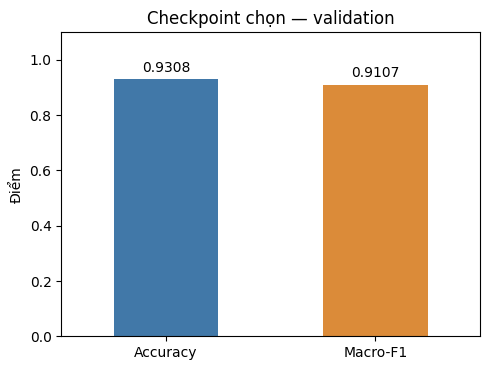

In [63]:
final_validation_scores = pd.Series({
    'Accuracy': validation_metrics['accuracy'], 'Macro-F1': validation_metrics['macro_f1'],
})
axis = final_validation_scores.plot.bar(figsize=(5, 3.8), color=['#4178A8', '#DB8B39'], rot=0)
axis.bar_label(axis.containers[0], fmt='%.4f', padding=3)
axis.set(title='Checkpoint chọn — validation', ylabel='Điểm', ylim=(0, 1.1))
axis.figure.tight_layout()
axis.figure.savefig(RUN_REPORT_DIR / 'selected_validation_scores.png', dpi=160)
plt.show()

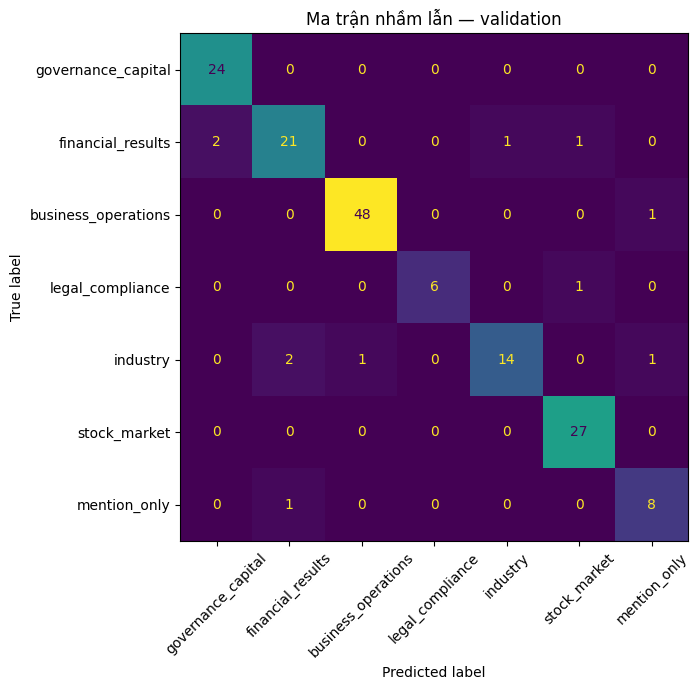

In [64]:
validation_confusion = confusion_matrix(
    validation_results['labels'], validation_results['predictions'], labels=list(range(NUM_CLASSES)),
)
figure, axis = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(validation_confusion, display_labels=ordered_labels).plot(
    ax=axis, xticks_rotation=45, colorbar=False,
)
axis.set_title('Ma trận nhầm lẫn — validation')
figure.tight_layout()
figure.savefig(RUN_REPORT_DIR / 'validation_confusion_matrix.png', dpi=160)
plt.show()

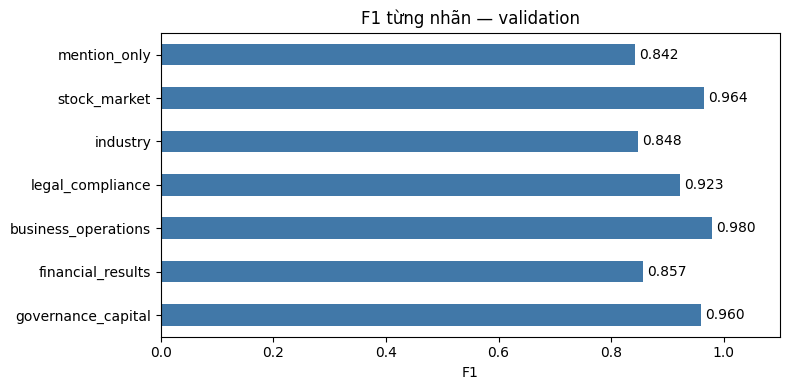

In [65]:
class_f1 = validation_class_report.loc[ordered_labels, 'f1-score']
axis = class_f1.plot.barh(figsize=(8, 4), color='#4178A8')
axis.bar_label(axis.containers[0], fmt='%.3f', padding=3)
axis.set(title='F1 từng nhãn — validation', xlabel='F1', ylabel='', xlim=(0, 1.1))
axis.figure.tight_layout()
axis.figure.savefig(RUN_REPORT_DIR / 'validation_class_f1.png', dpi=160)
plt.show()

In [66]:
if RUN_PARAMETER_STUDY and study_results is not None:
    selected_run_config = {
        **run_config, **{name: selected_config[name] for name in trial_columns[1:]},
        'study_name': STUDY_NAME, 'selected_trial_id': selected_trial_id,
        'best_epoch': selected_epoch, 'baseline_model_dir': str(baseline_model_dir),
        'best_validation_macro_f1': validation_metrics['macro_f1'],
    }
    tokenizer.save_pretrained(str(RUN_MODEL_DIR / 'tokenizer'))
    backbone.config.save_pretrained(str(RUN_MODEL_DIR / 'backbone'))
    (RUN_MODEL_DIR / 'run_config.json').write_text(
        json.dumps(selected_run_config, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )
    (RUN_REPORT_DIR / 'validation_metrics.json').write_text(
        json.dumps(validation_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )
    validation_class_report.to_csv(
        RUN_REPORT_DIR / 'validation_classification_report.csv', encoding='utf-8-sig',
    )

## 13. Rà lỗi validation

Đọc lại các bài mô hình dự đoán khác nhãn đã gán, rồi đối chiếu với số mẫu train để xác định nhóm cần bổ sung. Dùng kết quả của checkpoint vừa chọn; không huấn luyện lại, không dùng test và không tự sửa nhãn.

Bảng xếp theo F1 tăng dần, không phải quota gán nhãn. `false_negatives` là số bài của nhãn bị dự đoán sang nhóm khác; `false_positives` là số bài nhóm khác bị dự đoán vào nhãn này. Xác suất Softmax chưa hiệu chỉnh; bài bị cắt token cũng chưa chứng minh nguyên nhân dự đoán sai.

STT 16 và 18 đã được người gán xác nhận cùng giữ `financial_results`; lý do ở `resolved_reviews`. Validation vẫn gồm 159 bài. Hoàn tất rà nhãn không có nghĩa đã đánh giá test hoặc đã có kiểm định cuối độc lập.

In [67]:
if (validation_loader.dataset is not validation_dataset
        or not isinstance(validation_loader.sampler, SequentialSampler)
        or validation_loader.drop_last):
    raise ValueError('Validation phải dùng đúng dataset, giữ thứ tự và đủ mọi bài.')
dataset_labels = [int(record['labels']) for record in validation_dataset.records]
if dataset_labels != validation_data['label_id'].tolist():
    raise ValueError('Thứ tự nhãn trong validation dataset không khớp dữ liệu.')

In [68]:
validation_review, validation_errors, validation_confusion_pairs = build_validation_review(
    validation_data, train_data, validation_results, label2id,
    encodings=validation_encodings,
)
assert len(validation_errors) == int(validation_review['false_negatives'].sum())
print(f'Validation: {len(validation_errors)}/{len(validation_data)} bài dự đoán sai.')

Validation: 11/159 bài dự đoán sai.


In [69]:
review_columns = [
    'news_type', 'train_count', 'validation_count', 'false_negatives',
    'false_positives', 'f1', 'most_confused_with', 'confusion_count',
]
display(validation_review[review_columns].round({'f1': 4}))

,news_type,train_count,validation_count,false_negatives,false_positives,f1,most_confused_with,confusion_count
0,mention_only,59,9,1,2,0.8421,financial_results,1
1,industry,64,18,4,1,0.8485,financial_results,2
2,financial_results,124,25,4,3,0.8571,governance_capital,2
3,legal_compliance,36,7,1,0,0.9231,stock_market,1
4,governance_capital,106,24,0,2,0.9600,,0
5,stock_market,143,27,0,2,0.9643,,0
6,business_operations,208,49,1,1,0.9796,mention_only,1


In [70]:
display(validation_confusion_pairs)

,news_type,predicted_news_type,article_count
0,financial_results,governance_capital,2
1,industry,financial_results,2
2,business_operations,mention_only,1
3,financial_results,industry,1
4,financial_results,stock_market,1
5,industry,business_operations,1
6,industry,mention_only,1
7,legal_compliance,stock_market,1
8,mention_only,financial_results,1


In [71]:
error_columns = [
    'news_id', 'title', 'news_type', 'predicted_news_type',
    'predicted_probability', 'was_truncated',
]
with pd.option_context('display.max_colwidth', 90):
    display(validation_errors[error_columns].round({'predicted_probability': 4}))

,news_id,title,news_type,predicted_news_type,predicted_probability,was_truncated
0,501849a101dd8e0236562d421e0a872de2d689fd368199bb68fce0e9ede53b7c,"CEO Sabeco: Chúng tôi ủng hộ hoàn toàn Nghị định 100, đã uống thì không lái",industry,business_operations,0.9850,True
1,2bb5ece3d635099fa0cc711dd2d923b922bd900bca4777e499c45d141e0e1a1c,"Một doanh nghiệp có doanh thu vượt xa Vingroup, gấp đôi Thế Giới Di Động, Hòa Phát, Vi...",mention_only,financial_results,0.9846,True
2,0b13d1d4652ea2f6735c575c223f253cae9c6019375cf3438a4388e237267e52,Masan Hightech Materials tiến vào chu kỳ mới,financial_results,governance_capital,0.9769,True
3,5b8f634c90eb85e0c2e13dcdb96e53f6c31a2a96ddb0521a68cc86f67dd1672a,"Năm 2025, Sabeco đặt mục tiêu tăng trưởng 8%",financial_results,governance_capital,0.9397,True
4,081ffd5d006eb1fa37ee69e8dc48e275f09aa700cc793bffd147064c367e2c5f,"Đứt gãy nguồn cung, một kim loại tăng sát đỉnh lịch sử: SABECO hứng ""cú đấm"" vào biên ...",industry,financial_results,0.9381,True
5,fbcf249243dbfcd2cf5fe87a1c6b41a0882e610480d978389012a3ed6950c617,"Công an công bố kết quả giám định kim cương của PNJ, cổ phiếu tăng “bốc đầu”",legal_compliance,stock_market,0.8628,True
6,1d85806da71bbed30f87fb08768b156742ad9bb28ec7debb0b5f343c2eea0098,MWG Rank Among Top 20 Most Sustainable Companies By The Vietnam Sustainability Index (...,business_operations,mention_only,0.8570,True
7,f87ae72b4f4a4c4340f0e9ffe078a47561e828692a4595b906c09bfd665432b5,"Ai cũng buồn trong ""cuộc chiến giá"": TGDĐ ngậm ngùi đóng 200 cửa hàng, FPT Shop cũng đ...",industry,financial_results,0.4968,True
8,f52e0fbda1db9bac08cce9aef325ec5418d0ebc1047ce94729357c513728e68f,"Thanh tra SJC, Doji, PNJ, Bảo Tín Minh Châu kinh doanh vàng: Ai lỗ, lãi mạnh nhất?",financial_results,industry,0.4177,True
9,2401c9ffe6f50b99922e55b3b264a20cb7e18fc2590769c40ba4bd6399957e99,"Top 10 Công ty uy tín ngành Nông nghiệp Công nghệ cao năm 2025: CP, Lộc Trời từ top 1,...",industry,mention_only,0.3912,True


In [72]:
review_tables = {
    'validation_review_summary.csv': validation_review,
    'validation_errors.csv': validation_errors,
}
for filename, table in review_tables.items():
    table.to_csv(RUN_REPORT_DIR / filename, index=False, encoding='utf-8-sig')
print('Bảng rà lỗi:', RUN_REPORT_DIR)

Bảng rà lỗi: /content/drive/MyDrive/stock_news_anomaly_project/reports/news_type/evaluations/validation_review_20261025_v2


Ưu tiên đọc các nhóm F1 thấp và những cặp hay nhầm; đối chiếu nội dung bài với quy tắc gán nhãn trước khi quyết định bổ sung mẫu. Chỉ lấy bài mới ngoài validation/test, kiểm tra trùng và gần trùng. Không chuyển bài validation sang train hoặc đổi nhãn để khớp dự đoán.

## 14. Đánh giá test sau khi chốt cấu hình

Mặc định `EVALUATE_TEST = False`. Khi chốt cấu hình từ bảng validation, bật cờ này và chỉ chạy phần test. Không chọn lại cấu hình hoặc epoch vì kết quả test. Nếu tiếp tục điều chỉnh sau đó, test này không còn là phép đánh giá cuối độc lập.

Output test đang lưu thuộc lần chạy ngày 25/10/2026 khi đã bật `EVALUATE_TEST = True`. Sau lần đó, cờ được đặt lại `False`; kết quả đã lưu vẫn được giữ nguyên.

Biểu đồ tổng kết đặt Accuracy và Macro-F1 cạnh nhau, tách rõ validation với test. Xác suất Softmax trong file dự đoán chưa được hiệu chỉnh, không xem là độ tin cậy đã được kiểm chứng.

Sau khi có kết quả test thật, cell lưu hồ sơ test ràng buộc checkpoint, tokenizer, đầu vào và các báo cáo vừa xuất. Notebook 06 cần `test_evaluation_config.json` này trước khi gán nhãn tự động; việc thêm cell không tự bật hoặc chạy test.

In [73]:
if EVALUATE_TEST:
    test_data = split_frames['test']
    test_encodings = encode_news_texts(
        tqdm(test_data['input_text'], desc='Mã hóa test'), segmenter, tokenizer,
        max_length=MAX_LENGTH, head_ratio=HEAD_RATIO,
    )
    test_dataset = EncodedNewsDataset(test_encodings, test_data['label_id'].tolist())
    test_loader = DataLoader(
        test_dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=0, pin_memory=DEVICE.type == 'cuda',
    )
else:
    print('Chưa đánh giá test. Bật EVALUATE_TEST khi đã chốt cấu hình.')

Mã hóa test:   0%|          | 0/159 [00:00<?, ?it/s]

In [74]:
if EVALUATE_TEST:
    test_results = evaluate_classifier(model, test_loader, DEVICE, NUM_CLASSES, criterion)
    test_metrics = {name: test_results[name] for name in metric_names}
    test_class_report = pd.DataFrame(classification_report(
        test_results['labels'], test_results['predictions'],
        labels=list(range(NUM_CLASSES)), target_names=ordered_labels,
        output_dict=True, zero_division=0,
    )).T
    display(pd.DataFrame([test_metrics]).round(4))
    display(test_class_report.round(4))

,loss,accuracy,macro_f1,weighted_f1,balanced_accuracy
0,0.6757,0.8239,0.8038,0.8208,0.8169


,precision,recall,f1-score,support
governance_capital,0.7419,1.0000,0.8519,23.0000
financial_results,0.8214,0.8519,0.8364,27.0000
business_operations,0.8478,0.8667,0.8571,45.0000
legal_compliance,0.7778,1.0000,0.8750,7.0000
industry,0.9333,0.7778,0.8485,18.0000
stock_market,0.9091,0.6667,0.7692,30.0000
mention_only,0.6250,0.5556,0.5882,9.0000
accuracy,0.8239,0.8239,0.8239,0.8239
macro avg,0.8081,0.8169,0.8038,159.0000
weighted avg,0.8336,0.8239,0.8208,159.0000


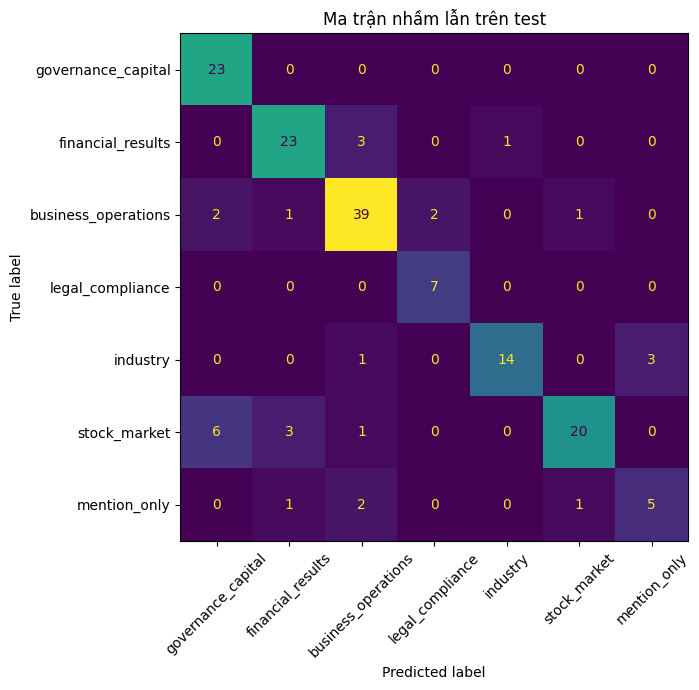

In [75]:
if EVALUATE_TEST:
    test_confusion_matrix = confusion_matrix(
        test_results['labels'], test_results['predictions'], labels=list(range(NUM_CLASSES)),
    )
    figure, axis = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(test_confusion_matrix, display_labels=ordered_labels).plot(
        ax=axis, xticks_rotation=45, colorbar=False,
    )
    axis.set_title('Ma trận nhầm lẫn trên test')
    figure.tight_layout()
    figure.savefig(RUN_REPORT_DIR / 'test_confusion_matrix.png', dpi=160)
    plt.show()

In [76]:
if EVALUATE_TEST:
    test_predictions = test_data[['news_id', 'source', 'news_type']].copy()
    test_predictions['predicted_news_type'] = [
        ordered_labels[label_id] for label_id in test_results['predictions']
    ]
    test_predictions['predicted_probability'] = test_results['probabilities'].max(axis=1)
    test_predictions['is_correct'] = test_predictions['news_type'].eq(
        test_predictions['predicted_news_type']
    )
    test_predictions.to_csv(
        RUN_REPORT_DIR / 'test_predictions.csv', index=False, encoding='utf-8-sig',
    )
    test_class_report.to_csv(RUN_REPORT_DIR / 'test_classification_report.csv', encoding='utf-8-sig')
    (RUN_REPORT_DIR / 'test_metrics.json').write_text(
        json.dumps(test_metrics, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )

In [77]:
if EVALUATE_TEST:
    test_evaluation_config = build_test_evaluation_manifest(
        RUN_MODEL_DIR, RUN_REPORT_DIR, input_sha256=input_file_hashes,
        label_mapping=label_mapping,
        validation_revision_sha256=(
            hashlib.sha256(VALIDATION_REVISION_PATH.read_bytes()).hexdigest()
            if evaluation_revision else None
        ),
        segmenter_sha256=segmenter_file_hashes,
        max_length=MAX_LENGTH, head_ratio=HEAD_RATIO, test_data=test_data,
    )
    (RUN_REPORT_DIR / 'test_evaluation_config.json').write_text(
        json.dumps(test_evaluation_config, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
    )
    print('Đã lưu hồ sơ test để notebook 06 đối chiếu:', RUN_REPORT_DIR)

Đã lưu hồ sơ test để notebook 06 đối chiếu: /content/drive/MyDrive/stock_news_anomaly_project/reports/news_type/evaluations/validation_review_20261025_v2


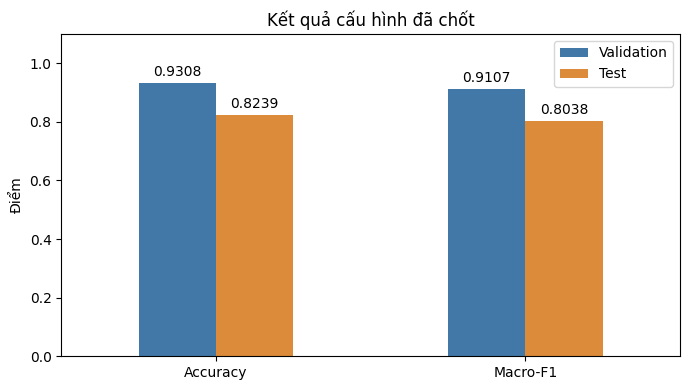

In [78]:
if EVALUATE_TEST:
    final_scores = pd.DataFrame({
        'Validation': {name: validation_metrics[name] for name in ('accuracy', 'macro_f1')},
        'Test': {name: test_metrics[name] for name in ('accuracy', 'macro_f1')},
    }).rename(index={'accuracy': 'Accuracy', 'macro_f1': 'Macro-F1'})
    axis = final_scores.plot.bar(figsize=(7, 4), color=['#4178A8', '#DB8B39'], rot=0)
    for bars in axis.containers:
        axis.bar_label(bars, fmt='%.4f', padding=3)
    axis.set(title='Kết quả cấu hình đã chốt', ylabel='Điểm', ylim=(0, 1.1))
    axis.figure.tight_layout()
    axis.figure.savefig(RUN_REPORT_DIR / 'final_accuracy_f1.png', dpi=160)
    plt.show()

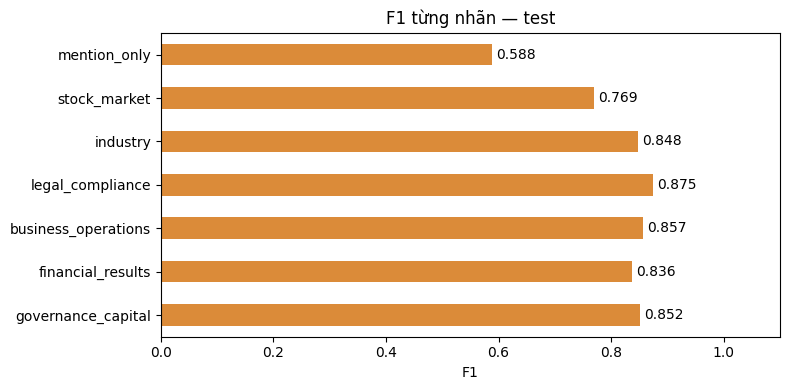

In [79]:
if EVALUATE_TEST:
    axis = test_class_report.loc[ordered_labels, 'f1-score'].plot.barh(
        figsize=(8, 4), color='#DB8B39',
    )
    axis.bar_label(axis.containers[0], fmt='%.3f', padding=3)
    axis.set(title='F1 từng nhãn — test', xlabel='F1', ylabel='', xlim=(0, 1.1))
    axis.figure.tight_layout()
    axis.figure.savefig(RUN_REPORT_DIR / 'test_class_f1.png', dpi=160)
    plt.show()

## Kết quả cần đọc

Ở chế độ một cấu hình, đọc đường học, Accuracy/Macro-F1 validation, F1 từng nhãn và bảng rà lỗi. Nếu bật khảo sát, đọc thêm bảng so sánh tham số. Một seed chưa đo được độ dao động giữa nhiều lần chạy; không kết luận từ riêng train loss hoặc một nhãn dễ.

Chỉ số test là kết quả sau khi chốt, không dùng để quay lại chọn tham số. Phép chia hiện tại không phải kiểm định theo thời gian, nên không dùng điểm này để khẳng định khả năng dự báo tin tương lai.

Tham khảo: [PhoBERT](https://huggingface.co/vinai/phobert-base-v2), [Cross-Entropy](https://docs.pytorch.org/docs/2.9/generated/torch.nn.CrossEntropyLoss.html), [tái lập trong PyTorch](https://docs.pytorch.org/docs/2.9/notes/randomness.html).